# Actuarial Baseline Models (GLM Framework)

This notebook trains and evaluates Generalized Linear Models (GLMs) as classical actuarial benchmarks:
1. **Frequency Model:** Poisson GLM with log link and $\ln(\text{Exposure})$ offset, using spline terms for non-linear age curves.
2. **Severity Model:** Gamma GLM with log link on positive attritional claims ($<€100\text{k}$).
3. **Two-Part Pure Premium:** $\hat{\pi} = \hat{\mu}_{\text{Freq}} \times \hat{\mu}_{\text{Sev}}$.
4. **Direct Tweedie GLM:** Single-stage compound Poisson-Gamma ($p=1.5$).
5. **Actuarial Evaluation:** Out-of-sample Poisson/Gamma/Tweedie deviance, Gini index, and rating relativities.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(".."))
from src.models import FrequencyPoissonGLM, SeverityGammaGLM, TweedieGLM, TwoPartGLM
from src.evaluation import poisson_deviance, gamma_deviance, tweedie_deviance, gini_coefficient

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

## 1. Train / Test Split (80 / 20)

In [2]:
df = pd.read_parquet("../data/processed/abt_motor_portfolio.parquet")
train_df, test_df = train_test_split(df, test_size=0.20, random_state=42, shuffle=True)

print(f"Train set: {len(train_df):,} policies ({train_df['Exposure_Capped'].sum():,.1f} years exposure)")
print(f"Test set:  {len(test_df):,} policies ({test_df['Exposure_Capped'].sum():,.1f} years exposure)")

Train set: 542,410 policies (286,585.0 years exposure)
Test set:  135,603 policies (71,775.1 years exposure)


## 2. Poisson Frequency GLM

In [3]:
freq_glm = FrequencyPoissonGLM()
freq_glm.fit(train_df, offset_col="LogExposure")

# Predictions on train and test
train_freq_pred = freq_glm.predict(train_df, offset_col="LogExposure")
test_freq_pred = freq_glm.predict(test_df, offset_col="LogExposure")

train_pois_dev = poisson_deviance(train_df["ClaimNb"], train_freq_pred, exposure=train_df["Exposure_Capped"])
test_pois_dev = poisson_deviance(test_df["ClaimNb"], test_freq_pred, exposure=test_df["Exposure_Capped"])
test_pois_gini = gini_coefficient(test_df["ClaimNb"], test_freq_pred, exposure=test_df["Exposure_Capped"])

print(f"Train Poisson Deviance: {train_pois_dev:.4f}")
print(f"Test Poisson Deviance:  {test_pois_dev:.4f}")
print(f"Test Frequency Gini:    {test_pois_gini:.4f}")

Train Poisson Deviance: 0.6043
Test Poisson Deviance:  0.6057
Test Frequency Gini:    0.2214


### Multiplicative Rating Factors (Ratebook Relativities)

In [4]:
params = freq_glm.results.params
conf = freq_glm.results.conf_int()

relativities_df = pd.DataFrame({
    "Coefficient (beta)": params,
    "Multiplicative Relativity (exp(beta))": np.exp(params),
    "CI Lower": np.exp(conf[0]),
    "CI Upper": np.exp(conf[1]),
    "p-value": freq_glm.results.pvalues
})

# Filter to discrete rating categories
cat_rel = relativities_df[relativities_df.index.str.contains("Area|VehGas|VehPower")]
cat_rel

,Coefficient (beta),Multiplicative Relativity (exp(beta)),CI Lower,CI Upper,p-value
C(Area)[T.B],0.011955,1.012026,0.957100,1.070106,6.745677e-01
C(Area)[T.C],-0.001351,0.998650,0.928846,1.073700,9.708567e-01
C(Area)[T.D],0.035714,1.036359,0.928767,1.156415,5.230795e-01
C(Area)[T.E],0.018606,1.018781,0.880267,1.179090,8.029383e-01
C(Area)[T.F],-0.058868,0.942831,0.770963,1.153014,5.664285e-01
C(VehGas)[T.Regular],0.063117,1.065151,1.039759,1.091163,2.940852e-07
VehPower,0.012654,1.012735,1.006638,1.018867,3.993243e-05


## 3. Gamma Severity GLM

In [5]:
sev_glm = SeverityGammaGLM()
sev_glm.fit(train_df)

# Evaluate on test positive attritional claims
test_claims = test_df[
    (test_df["HasClaim"] == 1) & 
    (test_df["AvgClaimSeverity"] > 0) & 
    (test_df["AvgClaimSeverity"] < 100000.0)
].copy()

test_sev_pred = sev_glm.predict(test_claims)
test_gamma_dev = gamma_deviance(test_claims["AvgClaimSeverity"], test_sev_pred)

print(f"Test Claims Evaluated: {len(test_claims):,}")
print(f"Test Gamma Deviance:   {test_gamma_dev:.4f}")
print(f"Mean Observed Severity:  €{test_claims['AvgClaimSeverity'].mean():,.2f}")
print(f"Mean Predicted Severity: €{test_sev_pred.mean():,.2f}")

Test Claims Evaluated: 4,956
Test Gamma Deviance:   1.2772
Mean Observed Severity:  €1,768.13
Mean Predicted Severity: €1,700.62


## 4. Pure Premium Models: Two-Part vs Direct Tweedie GLM

In [6]:
# 1. Two-Part Model (Frequency x Severity)
two_part_glm = TwoPartGLM(freq_glm=freq_glm, sev_glm=sev_glm)
test_twopart_pure_prem = two_part_glm.predict_pure_premium(test_df)

# 2. Direct Tweedie GLM
tweedie_glm = TweedieGLM(var_power=1.5)
tweedie_glm.fit(train_df, exposure_col="Exposure_Capped")
test_tweedie_pure_prem = tweedie_glm.predict(test_df)

# Compute Tweedie Deviances & Gini on Test Set
dev_twopart = tweedie_deviance(test_df["PurePremium"], test_twopart_pure_prem, p=1.5, weights=test_df["Exposure_Capped"])
dev_tweedie = tweedie_deviance(test_df["PurePremium"], test_tweedie_pure_prem, p=1.5, weights=test_df["Exposure_Capped"])

gini_twopart = gini_coefficient(test_df["PurePremium"], test_twopart_pure_prem, exposure=test_df["Exposure_Capped"])
gini_tweedie = gini_coefficient(test_df["PurePremium"], test_tweedie_pure_prem, exposure=test_df["Exposure_Capped"])

model_comp_df = pd.DataFrame({
    "Model Architecture": ["Two-Part GLM (Poisson x Gamma)", "Direct Tweedie GLM (p=1.5)"],
    "Test Tweedie Deviance": [dev_twopart, dev_tweedie],
    "Test Gini Index": [gini_twopart, gini_tweedie],
    "Mean Predicted Pure Premium": [f"€{test_twopart_pure_prem.mean():.2f}", f"€{test_tweedie_pure_prem.mean():.2f}"]
})
display(model_comp_df)

,Model Architecture,Test Tweedie Deviance,Test Gini Index,Mean Predicted Pure Premium
0,Two-Part GLM (Poisson x Gamma),77.682917,0.258657,€188.45
1,Direct Tweedie GLM (p=1.5),77.757910,0.269731,€195.80


## 5. Decile Calibration Analysis

,Decile,Policies,Exposure,Observed_Pure_Premium,Predicted_Pure_Premium
0,1,13561.0,8780.673528,55.761652,79.056931
1,2,13560.0,8623.889725,101.971276,98.639218
2,3,13560.0,8369.878311,126.241091,114.655521
3,4,13560.0,8065.709688,114.029833,131.475840
4,5,13561.0,7647.936146,105.479731,149.817820
5,6,13560.0,7101.579827,141.492623,169.991488
6,7,13560.0,6474.250801,164.124337,192.981338
7,8,13560.0,6040.202517,164.776171,221.897105
8,9,13560.0,5533.308788,211.593677,268.311899
9,10,13561.0,5137.653973,387.183783,458.431651


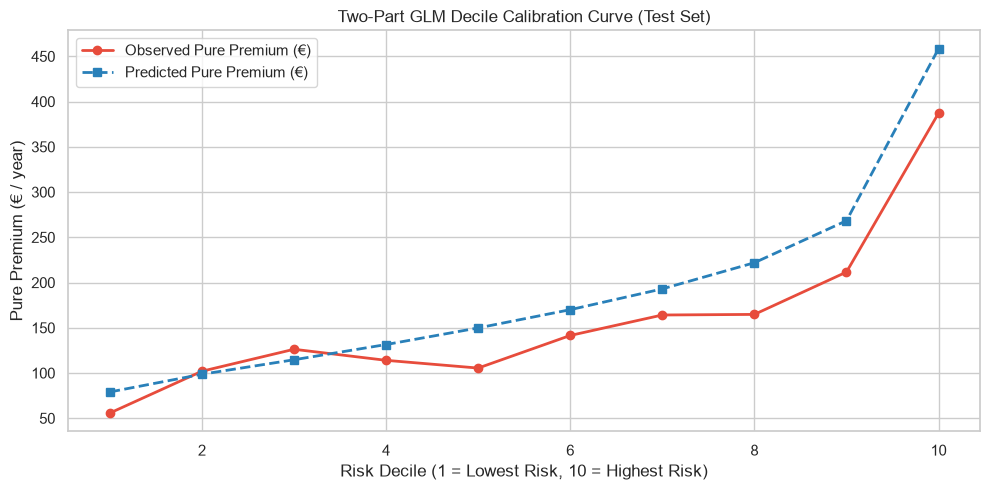

In [7]:
calib_df = test_df.copy()
calib_df["Pred_TwoPart"] = test_twopart_pure_prem
calib_df["Decile"] = pd.qcut(calib_df["Pred_TwoPart"], q=10, labels=False) + 1

decile_summary = calib_df.groupby("Decile").apply(
    lambda g: pd.Series({
        "Policies": len(g),
        "Exposure": g["Exposure_Capped"].sum(),
        "Observed_Pure_Premium": g["TotalClaimAmount"].sum() / g["Exposure_Capped"].sum(),
        "Predicted_Pure_Premium": np.average(g["Pred_TwoPart"], weights=g["Exposure_Capped"])
    })
).reset_index()

display(decile_summary)

plt.figure(figsize=(10, 5))
plt.plot(decile_summary["Decile"], decile_summary["Observed_Pure_Premium"], marker="o", lw=2, color="#e74c3c", label="Observed Pure Premium (€)")
plt.plot(decile_summary["Decile"], decile_summary["Predicted_Pure_Premium"], marker="s", lw=2, linestyle="--", color="#2980b9", label="Predicted Pure Premium (€)")
plt.title("Two-Part GLM Decile Calibration Curve (Test Set)", fontsize=12)
plt.xlabel("Risk Decile (1 = Lowest Risk, 10 = Highest Risk)")
plt.ylabel("Pure Premium (€ / year)")
plt.legend()
plt.tight_layout()
plt.show()